# XGBoost

This notebook trains an XGBoost model to predict the death risk of leukemia patients from clinical and molecular data.


The objective is therefore twofold:
1. Evaluate the ability of XGBoost to classify patients according to their risk.
2. Analyze the quality of its probabilities before any calibration.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.eval_utils import full_evaluation
from src.modeltrainer import ModelML, find_existing_model

## Load the processed data

The pairs built in `00_data_processing.ipynb` and imputed by `01_impute_missing_values.sh` are loaded from `data/processed_data_imputed.xlsx` (train / calibration / test sheets).

In [2]:
# =============================================================================
# CELL 1: LOAD DATA
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Load the three splits
print("Loading data...")

train_data = pd.read_excel(DATA_PATH, sheet_name='train')
cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Split features / target
X_train = train_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_train = train_data.iloc[:, -1]


X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print("Data loaded:")
print(f"   - Train: {X_train.shape[0]} lignes, {X_train.shape[1]} features")
print(f"   - Test: {X_test.shape[0]} lignes")
print(f"   - Target distribution (train): {y_train.value_counts().to_dict()}")

Loading data...
Data loaded:
   - Train: 445575 lignes, 81 features
   - Test: 56938 lignes
   - Target distribution (train): {0: 249063, 1: 196512}


In [3]:
# =============================================================================
# CELL 2: LOAD OR TRAIN THE XGBOOST MODEL
# =============================================================================


# Configuration
MODEL_DIR = 'models'
MODEL_TYPE = 'XGBoost'  # 'LogisticRegression', 'RandomForest', 'XGBoost'


# Initialise the trainer
trainer = ModelML(
    x_train=X_train,
    x_test=X_test,
    y_train=y_train,
    y_test=y_test
)

# Reuse a saved model if one exists, otherwise tune and train
existing_model = find_existing_model(MODEL_DIR, MODEL_TYPE)

if existing_model:
    print(f"Found saved model: {existing_model}")
    trainer.load_model(existing_model)
else:
    print(f"No saved {MODEL_TYPE} model found. Training...")
    
    trainer.tune_xgboost(
        param_grid={
            'n_estimators': [50, 100, 200],
            'max_depth': [3, 5, 7],
            'learning_rate': [0.01, 0.1],
            'subsample': [0.6, 0.8, 1.0]
        },
        method='random',
        n_iter=20,
        cv=5,
        scoring='roc_auc'
    )
    
    trainer.save_model()
    print("Model trained and saved")

print(f"\nActive model: {trainer.model_name}")
print(f"   Parameters: {trainer.best_params}")

No saved XGBoost model found. Training...

Hyperparameter search (RANDOM)
   Model: xgboost_tuned
   Scoring: roc_auc
   CV folds: 5
   Parameters searched: ['n_estimators', 'max_depth', 'learning_rate', 'subsample']
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best parameters found:
   - subsample: 0.8
   - n_estimators: 200
   - max_depth: 7
   - learning_rate: 0.1
   - Best CV Score (roc_auc): 0.9908

Results:
   - Train Accuracy: 0.9544
   - Test Accuracy:  0.6934
Model saved: models/xgboost_tuned.pkl
Parameters saved: models/xgboost_tuned_params.json
Model trained and saved

Active model: xgboost_tuned
   Parameters: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 7, 'learning_rate': 0.1}



FULL EVALUATION: xgboost_tuned_test
EVALUATION METRICS

Classification metrics:
----------------------------------------
   Accuracy                 : 0.6934
   Balanced_Accuracy        : 0.6873
   Precision                : 0.6761
   Recall_Sensitivity       : 0.6214
   Specificity              : 0.7531
   F1_Score                 : 0.6476
   Matthews_Corr_Coef       : 0.3782
   Cohen_Kappa              : 0.3771

Probabilistic metrics:
----------------------------------------
   ROC_AUC                  : 0.7609
   PR_AUC                   : 0.7190
   Brier_Score              : 0.2089
   Log_Loss                 : 0.6276

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Class 0       0.71      0.75      0.73     31128
     Class 1       0.68      0.62      0.65     25810

    accuracy                           0.69     56938
   macro avg       0.69      0.69      0.69     56938
weighted avg       0.69      0.69      0.69     56938


CONFUSION MATRIX



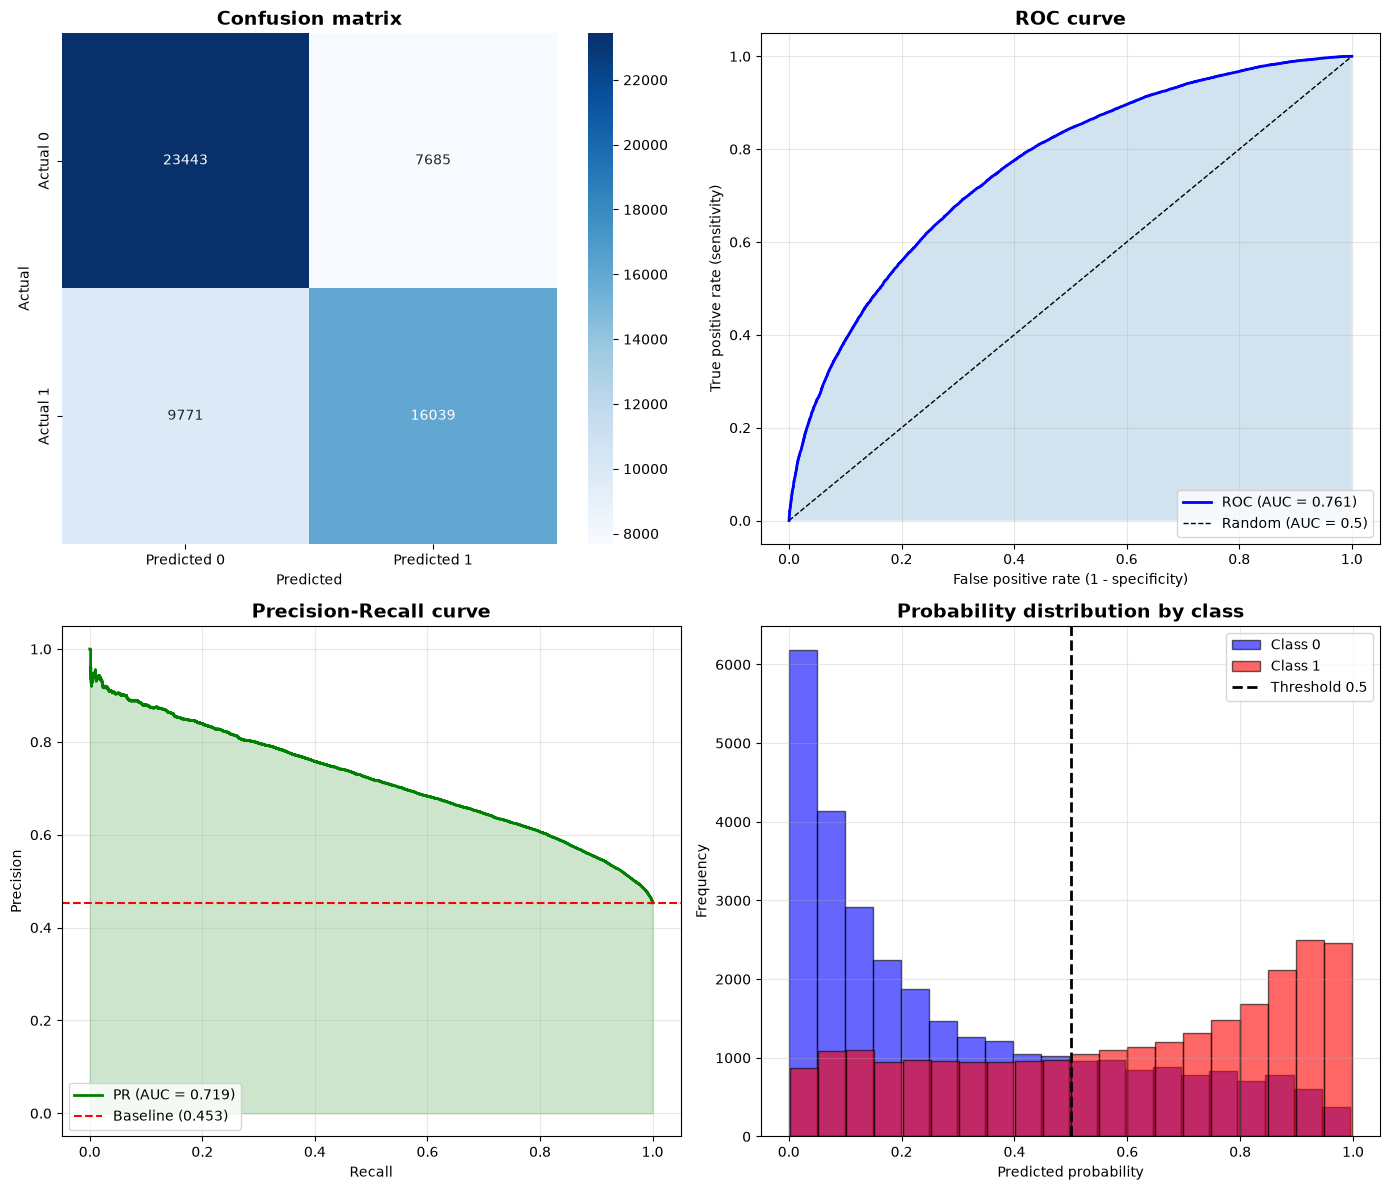

In [4]:
# =============================================================================
# CELL 3: FULL EVALUATION ON THE TEST SET
# =============================================================================


y_pred_test = trainer.predict(X_test)
y_proba_test = trainer.predict_proba(X_test)[:, 1]

metrics_test = full_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=f"{trainer.model_name}_test",
    save_dir='results'
)

# Show the plots
plt.show()

# XGBoost Results Analysis

### Model Performance (test pairs)
- **ROC-AUC: 0.761**: third of four models (logistic regression 0.776, random forest 0.770, gradient boosting 0.760)
- **Accuracy: 69.3%**
- **Brier Score: 0.209**: second highest, behind gradient boosting (0.211)
- **Log Loss: 0.628**: second highest, behind gradient boosting (0.646)

The gap between discrimination and probability quality points to **miscalibration** rather than weak ranking: the AUC is close to the other models, but the log loss is clearly worse. This is consistent with **overconfidence**( predicted probabilities pushed too close to 0 or 1.)
